In [1]:
# 01. Business Problem & Project Definition
USE_CASE = "15 - Order Value Prediction"
CATEGORY = "Regression"
OBJECTIVE = "Predict next order value of customers across SAP Sales Orders (VBAK, VBAP, KNA1, KNVV)."

print(f"Use Case:  {USE_CASE}")
print(f"Category:  {CATEGORY}")
print(f"Objective: {OBJECTIVE}")


Use Case:  15 - Order Value Prediction
Category:  Regression
Objective: Predict next order value of customers across SAP Sales Orders (VBAK, VBAP, KNA1, KNVV).


In [2]:
# 02. Import Required Libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from scipy.stats import pearsonr

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)


In [3]:
# 03. Connect to PostgreSQL Server (JKC_Input / HANA_P2 & HANA_P3)
from src.db_connector import load_config, get_db_engine

config = load_config()
engine = get_db_engine(config)

with engine.connect() as conn:
    print(f"Connected to PostgreSQL: {config['database']['host']}:{config['database']['port']}/{config['database']['dbname']} (Schema: {config['database']['schema']})")


Connected to PostgreSQL: 192.168.1.44:5432/JKC_Input (Schema: HANA_P3)


In [4]:
# 04. Extract Data from SAP Tables (VBAK, VBAP, KNA1, KNVV)
from src.db_connector import extract_order_value_data

# Extract sales order dataset from PostgreSQL server
nb_limit = config.get('query', {}).get('default_limit', 50000) or 50000
df_raw = extract_order_value_data(limit=nb_limit, config=config)
print(f"Extracted SAP Sales Orders: {len(df_raw):,} records, {df_raw.shape[1]} columns")


[INFO] Connecting to PostgreSQL at 192.168.1.44:5432 (JKC_Input)...
[INFO] Querying schema 'HANA_P3' for Sales Orders (VBAK), Item Metrics (VBAP), and Customers (KNA1)...
[INFO] Row extraction limit: 50,000 records.
[INFO] Successfully fetched 50,000 SAP sales order records from HANA_P3.
Extracted SAP Sales Orders: 50,000 records, 28 columns


In [5]:
# 05. Data Preview & Inspection
preview_cols = ['sales_order_id', 'order_date', 'customer_id', 'customer_name', 'order_type', 'order_net_value', 'total_items', 'total_quantity', 'plant']
print(f"Dataset Shape: {df_raw.shape}")
df_raw[preview_cols].head(10)


Dataset Shape: (50000, 28)


In [6]:
# 06. Exploratory Data Analysis (EDA) - Order Value Statistics
print("=== Numerical Summary of Order Values & Quantities ===")
df_raw[['order_net_value', 'total_items', 'total_quantity', 'avg_unit_price']].describe().T


=== Numerical Summary of Order Values & Quantities ===


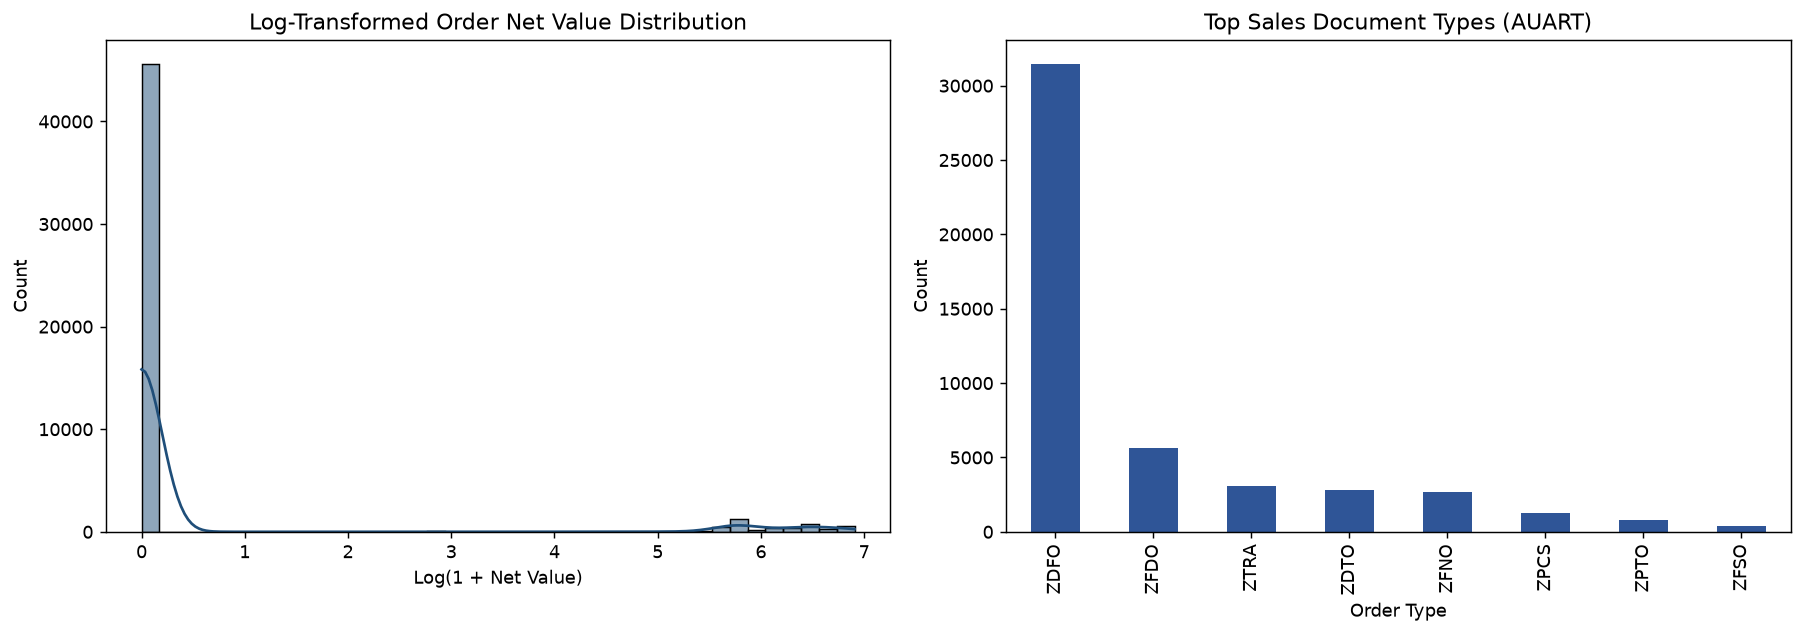

In [7]:
# 06. EDA Visualizations - Distribution of Order Value and Order Types
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.histplot(np.log1p(df_raw['order_net_value']), bins=40, kde=True, color='#1F4E79')
plt.title("Log-Transformed Order Net Value Distribution")
plt.xlabel("Log(1 + Net Value)")

plt.subplot(1, 2, 2)
df_raw['order_type'].value_counts().head(8).plot(kind='bar', color='#2F5597')
plt.title("Top Sales Document Types (AUART)")
plt.xlabel("Order Type")
plt.ylabel("Count")

plt.tight_layout()
plt.show()


In [8]:
# 07. Data Cleaning, Target Construction & 32 Feature Engineering
from src.preprocessing import clean_and_engineer_features, FEATURE_COLUMNS

featured_df = clean_and_engineer_features(df_raw)
print(f"Engineered Features Count: {len(FEATURE_COLUMNS)}")
print(f"Total Cleaned Records:     {len(featured_df):,}")
print(f"Trainable Order Pairs (Observed Next Order): {featured_df['next_order_value'].notna().sum():,} ({featured_df['next_order_value'].notna().mean()*100:.1f}%)")
print(f"Upcoming Orders (Forward Forecast):          {featured_df['next_order_value'].isna().sum():,} ({featured_df['next_order_value'].isna().mean()*100:.1f}%)")


Engineered Features Count: 32
Total Cleaned Records:     50,000
Trainable Order Pairs (Observed Next Order): 44,282 (88.6%)
Upcoming Orders (Forward Forecast):          5,718 (11.4%)


In [9]:
# 08. Regression Train/Test Split (80/20) & RobustScaler
from src.preprocessing import prepare_train_test_data

data_dict = prepare_train_test_data(featured_df, test_size=0.20, random_state=42)
X_train_scaled = data_dict['X_train_scaled']
X_test_scaled = data_dict['X_test_scaled']
y_train = data_dict['y_train']
y_test = data_dict['y_test']
scaler = data_dict['scaler']

print(f"X_train shape: {X_train_scaled.shape}")
print(f"X_test shape:  {X_test_scaled.shape}")


X_train shape: (35425, 32)
X_test shape:  (8857, 32)


In [10]:
# 09. Train 5 Supervised Regression ML Models
from src.models import OrderValueRegressionSuite

suite = OrderValueRegressionSuite(random_state=42)
suite.train_all(X_train_scaled, y_train)
print("All 5 Supervised Regression Models Trained Successfully!")


[INFO] Training Regression Model 1/5: Random Forest Regressor...
[INFO] Training Regression Model 2/5: Gradient Boosting Regressor...
[INFO] Training Regression Model 3/5: HistGradientBoosting Regressor...
[INFO] Training Regression Model 4/5: Decision Tree Regressor...
[INFO] Training Regression Model 5/5: Ridge Regressor...
All 5 Supervised Regression Models Trained Successfully!


In [11]:
# 10. Evaluate Accuracy & Rank the 5 Models on Test Split
from src.evaluate import evaluate_models

test_preds = suite.predict_all(X_test_scaled)
comparison_df = evaluate_models(test_preds, y_test)

print("=" * 96)
print("  5 SUPERVISED REGRESSION MODELS EVALUATION & RANKING TABLE")
print("=" * 96)
display(comparison_df)


  5 SUPERVISED REGRESSION MODELS EVALUATION & RANKING TABLE
  Rank                           Model  ... Accuracy (±20%)  Pearson r
0   #1  HistGradientBoosting Regressor  ...            1.45     0.8442
1   #2         Random Forest Regressor  ...           11.35     0.8437
2   #3                 Ridge Regressor  ...            3.39     0.8391
3   #4     Gradient Boosting Regressor  ...            1.50     0.8340
4   #5         Decision Tree Regressor  ...            3.27     0.8277

[5 rows x 9 columns]


[INFO] Saved regression model comparison chart to reports/figures\model_comparison_metrics.png
[INFO] Saved Actual vs Predicted chart to reports/figures\actual_vs_predicted.png
[INFO] Saved residuals distribution chart to reports/figures\residuals_distribution.png


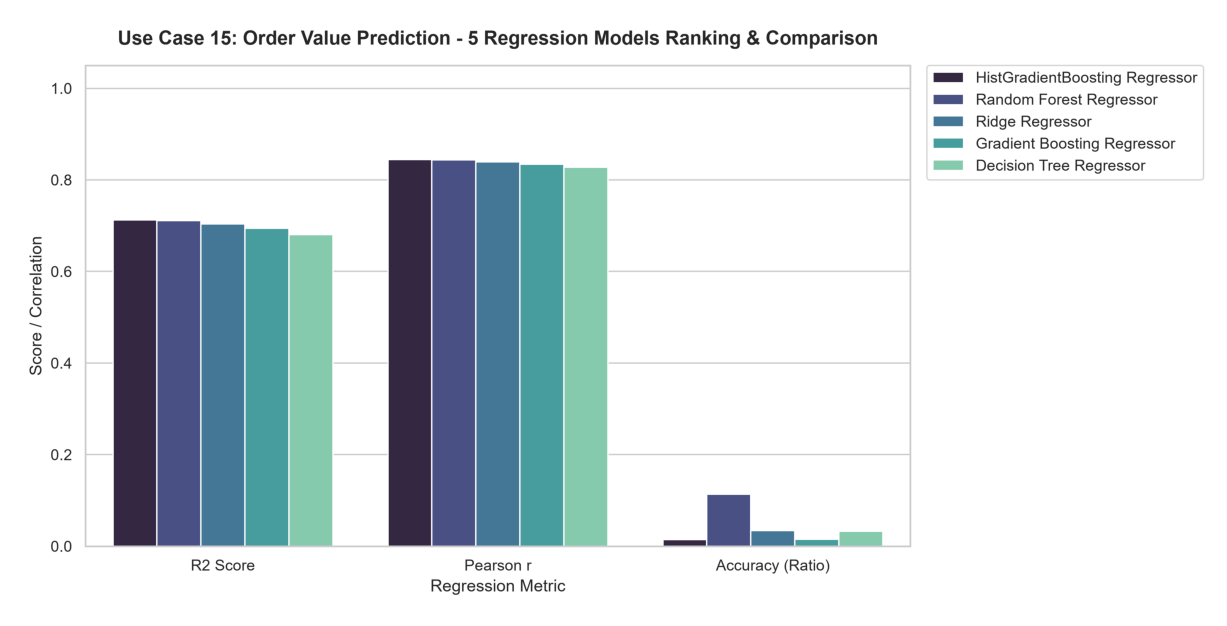

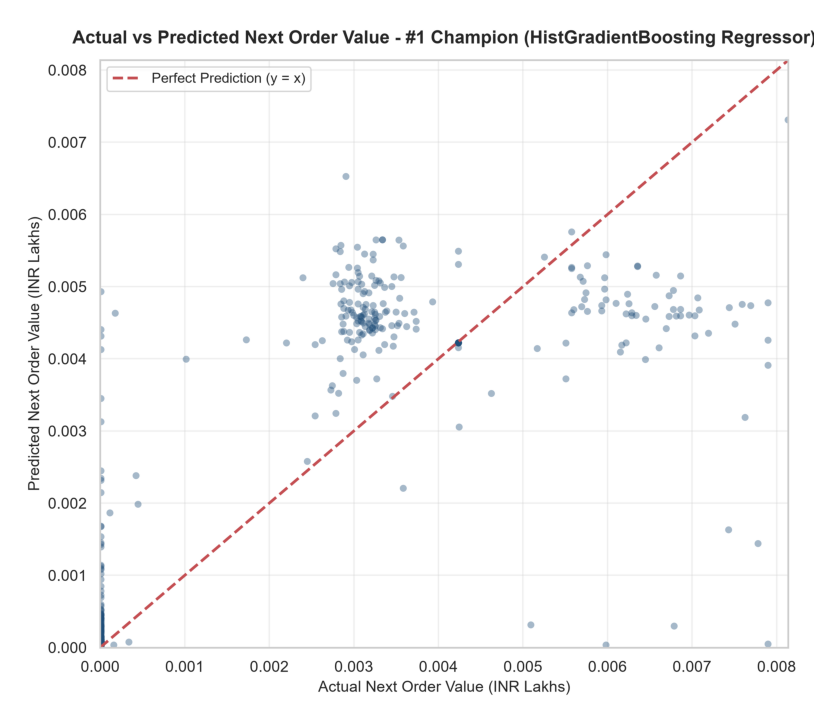

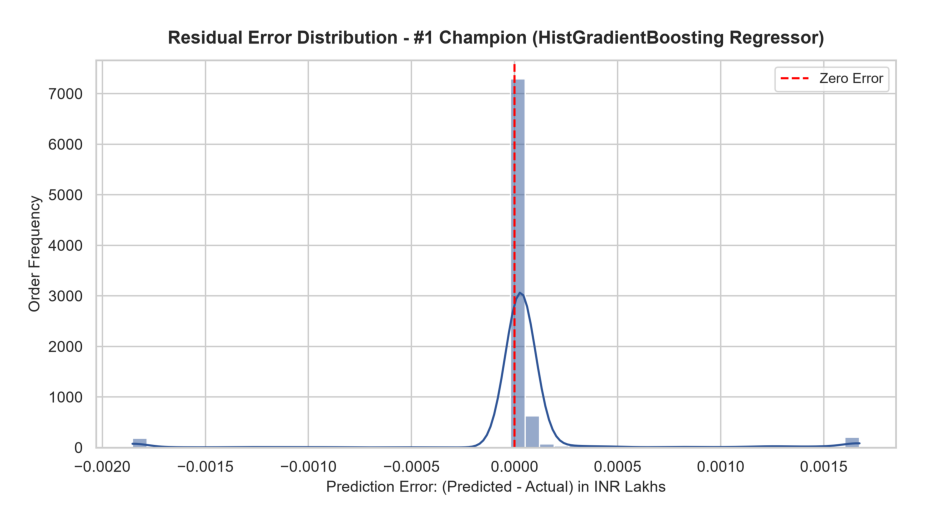

In [12]:
# 11. Visualizations: Model Comparison & Regression Diagnostics
from src.evaluate import plot_model_comparison, plot_actual_vs_predicted, plot_residuals_distribution

os.makedirs("reports/figures", exist_ok=True)
plot_model_comparison(comparison_df, output_dir="reports/figures")

champion_key = comparison_df.iloc[0]['model_key']
champion_name = comparison_df.iloc[0]['Model']
plot_actual_vs_predicted(y_test, test_preds[champion_key], champion_name, output_dir="reports/figures")
plot_residuals_distribution(y_test, test_preds[champion_key], champion_name, output_dir="reports/figures")

# Display in notebook
fig_comp = plt.imread("reports/figures/model_comparison_metrics.png")
plt.figure(figsize=(12, 6))
plt.imshow(fig_comp)
plt.axis('off')
plt.show()

fig_reg = plt.imread("reports/figures/actual_vs_predicted.png")
plt.figure(figsize=(8, 7))
plt.imshow(fig_reg)
plt.axis('off')
plt.show()

fig_res = plt.imread("reports/figures/residuals_distribution.png")
plt.figure(figsize=(9, 5))
plt.imshow(fig_res)
plt.axis('off')
plt.show()


In [13]:
# 12. Select #1 Champion Regression Model
champion_row = comparison_df.iloc[0]
print(f"Rank #1 Champion Model: {champion_name}")
print(f"R2 Score:        {champion_row['R2 Score']:.4f}")
print(f"MAE (INR):       INR {champion_row['MAE (INR)']:,.2f}")
print(f"RMSE (INR):      INR {champion_row['RMSE (INR)']:,.2f}")
print(f"Accuracy (+-20%): {champion_row['Accuracy (±20%)']}%")
print(f"Pearson r:       {champion_row['Pearson r']:.4f}")


Rank #1 Champion Model: HistGradientBoosting Regressor
R2 Score:        0.7126
MAE (INR):       INR 21.70
RMSE (INR):      INR 79.34
Accuracy (+-20%): 1.45%
Pearson r:       0.8442


In [14]:
# 13. Production Scoring for Next Order Value with Champion Model
from src.models import SingleModelOrderValueRegressor
from src.inference import score_with_single_model

regressor = SingleModelOrderValueRegressor(
    random_state=42,
    pretrained_model=suite.models[champion_key]
)

scored_df = score_with_single_model(featured_df, regressor, scaler, FEATURE_COLUMNS)
print(f"Scored Records: {len(scored_df):,}")
display(scored_df[['sales_order_id', 'customer_id', 'customer_name', 'order_net_value', 'predicted_next_order_value', 'actual_next_order_value', 'expected_growth_trend', 'predicted_value_tier']].head(10))


Scored Records: 50,000
  sales_order_id  ...                      predicted_value_tier
0     2132440988  ...  Tier 4 - Standard Retail (< INR 100,000)
1     2131392711  ...  Tier 4 - Standard Retail (< INR 100,000)
2     2132086667  ...  Tier 4 - Standard Retail (< INR 100,000)
3     2132087102  ...  Tier 4 - Standard Retail (< INR 100,000)
4     2132087115  ...  Tier 4 - Standard Retail (< INR 100,000)
5     2132093820  ...  Tier 4 - Standard Retail (< INR 100,000)
6     2132095687  ...  Tier 4 - Standard Retail (< INR 100,000)
7     2132098941  ...  Tier 4 - Standard Retail (< INR 100,000)
8     2132102272  ...  Tier 4 - Standard Retail (< INR 100,000)
9     2132102474  ...  Tier 4 - Standard Retail (< INR 100,000)

[10 rows x 8 columns]


=== Predicted Value Tier Breakdown ===
predicted_value_tier
Tier 4 - Standard Retail (< INR 100,000)    50000
Name: count, dtype: int64

=== Expected Growth Trend Breakdown ===
expected_growth_trend
Expansion Expected (+15%+)                 47558
Contraction / Down-Trading Risk (-15%-)     1803
Stable / Routine Run-Rate (±15%)             639
Name: count, dtype: int64


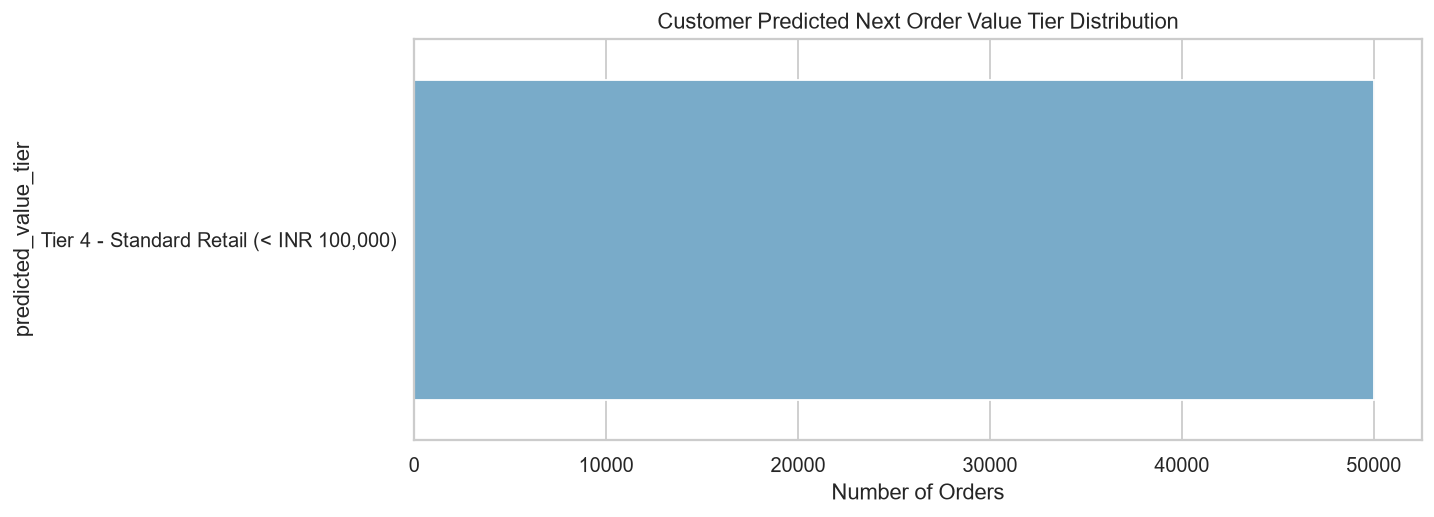

In [15]:
# 14. Predicted Value Tiers & Customer Growth Trends Breakdown
print("=== Predicted Value Tier Breakdown ===")
display(scored_df['predicted_value_tier'].value_counts())

print("")
print("=== Expected Growth Trend Breakdown ===")
display(scored_df['expected_growth_trend'].value_counts())

plt.figure(figsize=(10, 4))
sns.countplot(data=scored_df, y='predicted_value_tier', palette='Blues_r')
plt.title("Customer Predicted Next Order Value Tier Distribution")
plt.xlabel("Number of Orders")
plt.show()


[INFO] Saved feature importance chart to reports/figures\feature_importance.png
=== Top 15 Feature Importances ===
                         Feature  Importance
0                order_net_value     0.03125
1            log_order_net_value     0.03125
2                    total_items     0.03125
3                 total_quantity     0.03125
4             log_total_quantity     0.03125
5                 avg_unit_price     0.03125
6             log_avg_unit_price     0.03125
7                 max_item_value     0.03125
8             distinct_materials     0.03125
9             total_gross_weight     0.03125
10              log_gross_weight     0.03125
11          customer_order_count     0.03125
12      customer_avg_order_value     0.03125
13  log_customer_avg_order_value     0.03125
14      customer_std_order_value     0.03125


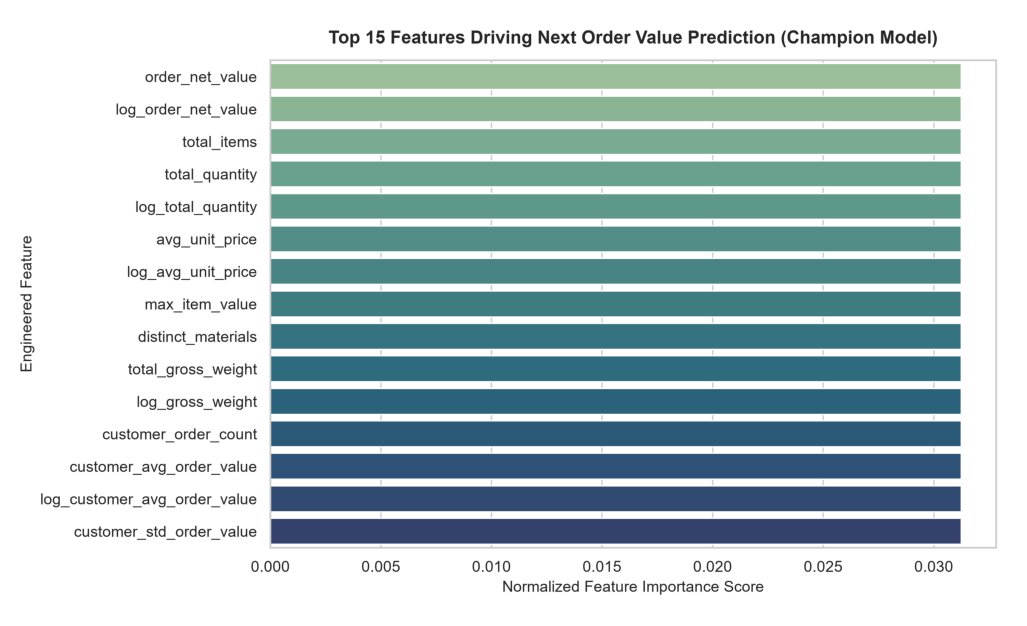

In [16]:
# 15. Feature Importance & Explainability
from src.evaluate import compute_feature_importance, plot_feature_importance

feat_imp = compute_feature_importance(regressor.model, FEATURE_COLUMNS)
plot_feature_importance(feat_imp, output_dir="reports/figures")

print("=== Top 15 Feature Importances ===")
display(feat_imp.head(15))

fig_fi = plt.imread("reports/figures/feature_importance.png")
plt.figure(figsize=(10, 6))
plt.imshow(fig_fi)
plt.axis('off')
plt.show()


In [17]:
# 16. Export Executive Multi-Sheet Excel Report with Feature_Importance & Missing Value Sanitization
from src.inference import export_enriched_excel_report, save_single_model_pipeline

output_excel = "ML_15_Order_Value_Prediction_Enriched_Output_Clean.xlsx"
desc = "Predict next order value of customers using Supervised Machine Learning Regression across SAP VBAK, VBAP, KNA1, KNVV."

export_enriched_excel_report(
    df=scored_df,
    output_path=output_excel,
    insight_id="ML_15",
    use_case="Order Value Prediction",
    description=desc,
    evaluation_df=comparison_df,
    feature_importance_df=feat_imp
)

# Export standard copy
export_enriched_excel_report(
    df=scored_df,
    output_path="ML_15_Order_Value_Prediction_Enriched_Output.xlsx",
    insight_id="ML_15",
    use_case="Order Value Prediction",
    description=desc,
    evaluation_df=comparison_df,
    feature_importance_df=feat_imp
)

save_single_model_pipeline(regressor, "models/champion_order_value_regressor.joblib")
print("All reports, metrics, and models generated successfully!")


[INFO] Successfully exported Regression Excel report with Feature_Importance to: ML_15_Order_Value_Prediction_Enriched_Output_Clean.xlsx
[INFO] Exported 100% full scored dataset (50,000 records) to: ML_15_Order_Value_Prediction_Enriched_Output_Full.csv
[INFO] Successfully exported Regression Excel report with Feature_Importance to: ML_15_Order_Value_Prediction_Enriched_Output.xlsx
[INFO] Exported 100% full scored dataset (50,000 records) to: ML_15_Order_Value_Prediction_Enriched_Output_Full.csv
[INFO] Saved #1 Champion Regression Model to models/champion_order_value_regressor.joblib
All reports, metrics, and models generated successfully!
